In [2]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM


/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [3]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [305]:
############# Upload data ###########
response_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/response_matrix_train.npy' )
response_matrix_train  = response_matrix_train[:50,:]
condition_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/condition_matrix_train.npy' )
condition_matrix_train  = condition_matrix_train[:50,:]

restriction = np.std(response_matrix_train, axis=(0, 1, 2)) > .01
response_matrix_train = response_matrix_train[
    :, :, :, restriction]

N_NEURONS = response_matrix_train.shape[3]

# response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
#
# response_matrix_train = torch.tensor(response_matrix_train).float()

In [306]:

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])

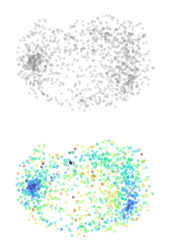

In [308]:
#########################################################################
################ Time series embedding for bwm data  ####################
#########################################################################
#x_proj = model.encoder(torch.tensor(response_matrix.T).float()).detach().numpy()

fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])


responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                             keepdims=True)) / np.std(response_matrix_train,
                                                                      axis=(0, 1, 2),
                                                                      keepdims=True)

data_snr = []
for neuron in range(N_NEURONS):
    means = []
    for t in range(99):
        h = (responses[:, 0, t + 1, neuron] - responses[:, 0, t, neuron]) / (responses[:, 0, t, neuron] + 5)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])


x_proj = TSNE(n_components = 2,perplexity = 200).fit_transform(response_matrix.T)

# # import umap
# fit = umap.UMAP(densmap=True,dens_lambda=5)
# x_proj= fit.fit_transform(response_matrix.T)

sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .25,color='gray')
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data_snr,palette = 'turbo')

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [ ]:
# Volume preserving VAE

Epoch 0 | Beta: 0.00 | Loss: 220136.22
Epoch 20 | Beta: 0.40 | Loss: 129629.46
Epoch 40 | Beta: 0.80 | Loss: 106322.28
Epoch 60 | Beta: 1.00 | Loss: 88027.89
Epoch 80 | Beta: 1.00 | Loss: 85692.92
Epoch 100 | Beta: 1.00 | Loss: 84522.48
Epoch 120 | Beta: 1.00 | Loss: 83399.22
Epoch 140 | Beta: 1.00 | Loss: 81922.14
Epoch 160 | Beta: 1.00 | Loss: 80031.93
Epoch 180 | Beta: 1.00 | Loss: 77395.07
Epoch 200 | Beta: 1.00 | Loss: 74210.84
Epoch 220 | Beta: 1.00 | Loss: 71361.98
Epoch 240 | Beta: 1.00 | Loss: 69265.02
Epoch 260 | Beta: 1.00 | Loss: 68008.92
Epoch 280 | Beta: 1.00 | Loss: 66649.67
Epoch 300 | Beta: 1.00 | Loss: 65609.84
Epoch 320 | Beta: 1.00 | Loss: 64896.47
Epoch 340 | Beta: 1.00 | Loss: 63774.53
Epoch 360 | Beta: 1.00 | Loss: 63228.30
Epoch 380 | Beta: 1.00 | Loss: 63107.87
Epoch 400 | Beta: 1.00 | Loss: 62040.10
Epoch 420 | Beta: 1.00 | Loss: 62155.79
Epoch 440 | Beta: 1.00 | Loss: 61138.87
Epoch 460 | Beta: 1.00 | Loss: 60625.87
Epoch 480 | Beta: 1.00 | Loss: 60573.90
Epo

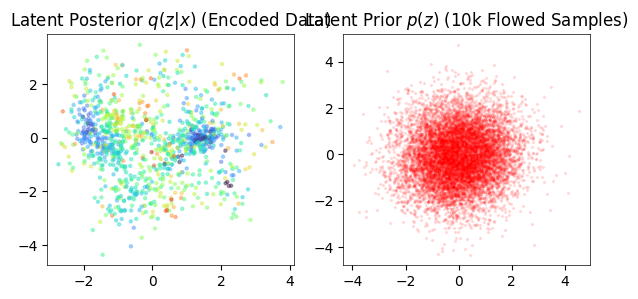

In [240]:
model, spherical_data = train_model()

Epoch 0 | Loss: 88650.61
Epoch 20 | Loss: 11247.91
Epoch 40 | Loss: 7238.18
Epoch 60 | Loss: 6115.04
Epoch 80 | Loss: 5491.45
Epoch 100 | Loss: 5131.51
Epoch 120 | Loss: 4919.99
Epoch 140 | Loss: 4716.88
Epoch 160 | Loss: 4596.35
Epoch 180 | Loss: 4423.04
Epoch 200 | Loss: 4273.82
Epoch 220 | Loss: 4270.43
Epoch 240 | Loss: 4216.87
Epoch 260 | Loss: 4178.51
Epoch 280 | Loss: 4131.65
Epoch 300 | Loss: 4134.05
Epoch 320 | Loss: 4091.40
Epoch 340 | Loss: 4160.39
Epoch 360 | Loss: 4116.85
Epoch 380 | Loss: 4098.31
Epoch 400 | Loss: 4065.49
Epoch 420 | Loss: 3993.74
Epoch 440 | Loss: 4006.61
Epoch 460 | Loss: 4045.17
Epoch 480 | Loss: 4029.73
Epoch 500 | Loss: 3994.00
Epoch 520 | Loss: 4015.61
Epoch 540 | Loss: 4044.36
Epoch 560 | Loss: 3968.96
Epoch 580 | Loss: 4021.11
Epoch 600 | Loss: 4065.38
Epoch 620 | Loss: 3961.16
Epoch 640 | Loss: 3992.52
Epoch 660 | Loss: 3965.44
Epoch 680 | Loss: 3949.38
Epoch 700 | Loss: 4057.06
Epoch 720 | Loss: 4010.83
Epoch 740 | Loss: 3945.03
Epoch 760 | Loss

Epoch 0, Loss: 182.6907
Epoch 10, Loss: 73.6077
Epoch 20, Loss: 67.1330
Epoch 30, Loss: 62.5381
Epoch 40, Loss: 60.3490


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_73884/3559447603.py:147: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


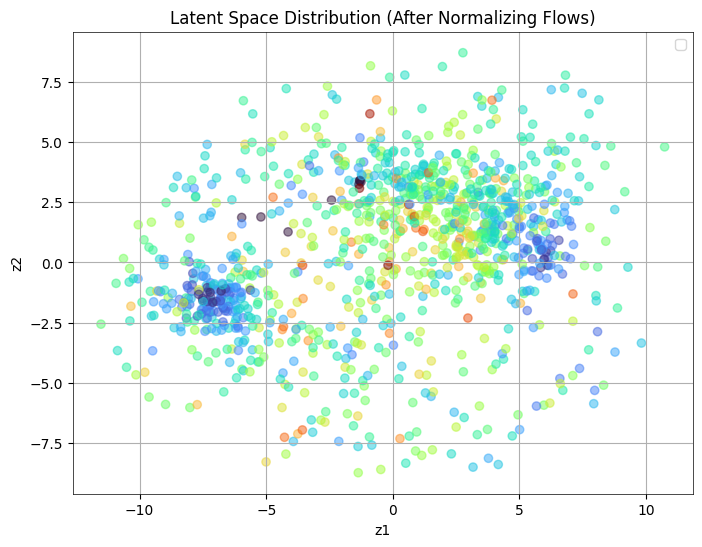

In [318]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Planar Flow Layer ---
class PlanarFlow(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.w = nn.Parameter(torch.randn(1, dim) * 0.01)
        self.b = nn.Parameter(torch.randn(1) * 0.01)
        self.u = nn.Parameter(torch.randn(1, dim) * 0.01)

    def h(self, x):
        return torch.tanh(x)

    def h_prime(self, x):
        return 1 - torch.tanh(x) ** 2

    def forward(self, z):
        # Ensure invertibility condition: w^T * u > -1
        # Simple heuristic: u_hat = u + (m(w^T * u) - w^T * u) * (w / ||w||^2)
        inner = torch.mm(self.u, self.w.t())
        u_hat = self.u + ((-1 + torch.log1p(torch.exp(inner))) - inner) * (self.w / torch.norm(self.w)**2)

        # Transformation: f(z) = z + u*h(w*z + b)
        activation = torch.mm(z, self.w.t()) + self.b
        z_next = z + u_hat * self.h(activation)

        # Log-determinant of Jacobian
        psi = self.h_prime(activation) * self.w
        det_grad = 1 + torch.mm(psi, u_hat.t())
        ldj = torch.log(det_grad.abs() + 1e-9)

        return z_next, ldj

# --- 2. VAE with Flows Model ---
class FlowVAE(nn.Module):
    def __init__(self, input_dim=200, latent_dim=2, n_flows=4):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 64),

        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Normalizing Flows
        self.flows = nn.ModuleList([PlanarFlow(latent_dim) for _ in range(n_flows)])

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 128),
            nn.Tanh(),
            nn.Linear(128, input_dim),

        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z_0 = self.reparameterize(mu, logvar)

        # Initial log probability
        log_q0 = -0.5 * torch.sum(logvar + (z_0 - mu)**2 / torch.exp(logvar), dim=1)

        # Apply flows
        z_k = z_0
        sum_ldj = 0
        for flow in self.flows:
            z_k, ldj = flow(z_k)
            sum_ldj += ldj.squeeze()

        log_qk = log_q0 - sum_ldj
        x_recon = self.decoder(z_k)

        return x_recon, mu, logvar, z_k, log_qk

# --- 3. Training Logic ---
def train_model():
    # Params
    input_dim = 200
    latent_dim = 2
    batch_size = 64
    epochs = 50

    model = FlowVAE(input_dim, latent_dim)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    mse_loss = nn.MSELoss(reduction='sum')

    # Dummy Data: Clustered distributions in 200D space
    data = torch.FloatTensor(response_matrix.T)

    model.train()
    for epoch in range(epochs):
        total_loss = 0
        perm = torch.randperm(data.size(0))

        for i in range(0, data.size(0), batch_size):
            idx = perm[i:i+batch_size]
            batch = data[idx]

            optimizer.zero_grad()
            recon, mu, logvar, z_k, log_qk = model(batch)

            # MSE Loss
            recon_loss = mse_loss(recon, batch)

            # KLD with Flows: E[log q_k(z_k) - log p(z_k)]
            # log p(z_k) is simple Gaussian prior
            log_pk = -0.5 * torch.sum(z_k**2, dim=1)
            kld_loss = torch.mean(log_qk - log_pk)

            loss = recon_loss + kld_loss
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {total_loss / data.size(0):.4f}")

    # --- 4. Plotting ---
    model.eval()
    with torch.no_grad():
        _, _, _, z_final, _ = model(data)
        z_final = z_final.numpy()

    plt.figure(figsize=(8, 6))
    plt.scatter(z_final[:, 0], z_final[:, 1], alpha=0.5, c = data_snr, cmap='turbo')
   # plt.scatter(z_final[500:, 0], z_final[500:, 1], alpha=0.5, label='Cluster 2')
    plt.title("Latent Space Distribution (After Normalizing Flows)")
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    train_model()

In [347]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

# --- 1. RealNVP Architecture (Same as before) ---
class CouplingLayer(nn.Module):
    def __init__(self, dim, hidden_dim, mask):
        super().__init__()
        self.mask = mask
        self.scale_net = nn.Sequential(
            nn.Linear(dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, dim), nn.Tanh()
        )
        self.trans_net = nn.Sequential(
            nn.Linear(dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, dim)
        )

    def forward(self, x):
        x1 = x * self.mask
        s = self.scale_net(x1) * (1 - self.mask)
        t = self.trans_net(x1) * (1 - self.mask)
        y = x1 + (1 - self.mask) * (x * torch.exp(s) + t)
        log_det = torch.sum(s, dim=1)
        return y, log_det

class MDFlow(nn.Module):
    def __init__(self, D, d, hidden_dim=128, num_layers=6):
        super().__init__()
        self.D = D
        self.d = d
        self.layers = nn.ModuleList()
        for i in range(num_layers):
            mask = torch.zeros(D)
            # Alternate masking for better mixing
            mask[np.arange(i % 2, D, 2)] = 1
            self.layers.append(CouplingLayer(D, hidden_dim, mask))

    def forward(self, x):
        log_det_total = 0
        z = x
        for layer in self.layers:
            z, log_det = layer(z)
            log_det_total += log_det
        return z, log_det_total

    def get_md_loss(self, x, lambd=1.0):
        """
        Implements the M/D strategy.
        lambd: Weight for the manifold reconstruction (Distance) term.
        """
        z_full, log_det = self.forward(x)

        # Split dimensions
        z = z_full[:, :self.d]
        u = z_full[:, self.d:]

        # 1. 'M' Step: Density estimation on the manifold
        log_pz = -0.5 * torch.sum(z**2, dim=1) - 0.5 * self.d * np.log(2 * np.pi)
        loss_m = -(log_pz + log_det).mean()

        # 2. 'D' Step: Manifold reconstruction (Distance from manifold)
        # We want u (the noise/orthogonal dims) to be zero.
        loss_d = torch.mean(torch.sum(u**2, dim=1))

        total_loss = loss_m + (lambd * loss_d)
        return total_loss, loss_m, loss_d

# --- 2. Synthetic Neuron-like Data (n_neurons=100, features=200) ---
n_neurons = 1000
D = 200
d = 2  # Hypothesized intrinsic dimensionality

# # Create a 2D manifold embedded in 200D
# X_raw, _ = make_swiss_roll(n_samples=n_neurons, noise=0.1)
# X_high_d = np.zeros((n_neurons, D))
# X_high_d[:, :3] = X_raw
# X_high_d += np.random.normal(0, 0.01, size=(n_neurons, D))
X_tensor = torch.FloatTensor(response_matrix.T)

# --- 3. Training with M/D Strategy ---
model = MDFlow(D=D, d=d)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# M/D Strategy: Often starts with a high lambda to find the manifold,
# then decreases it to refine the density.
lambd = 100.0

print(f"Training with M/D Strategy (D={D}, d={d})...")
for epoch in range(6000):
    optimizer.zero_grad()

    # Gradually decay lambda or keep it fixed depending on the specific manifold complexity
    current_lambd = max(1.0, lambd * (0.995 ** (epoch // 10)))
    current_lambd = lambd
    total_loss, m_loss, d_loss = model.get_md_loss(X_tensor, lambd=current_lambd)
    total_loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch:4} | M-Loss (Density): {m_loss.item():8.2f} | D-Loss (Manifold): {d_loss.item():8.6f} | Lambda: {current_lambd:.2f}")

# --- 4. Plotting ---
model.eval()
with torch.no_grad():
    z_full, _ = model.forward(X_tensor)
    z_latents = z_full[:, :d].numpy()



Training with M/D Strategy (D=200, d=2)...
Epoch    0 | M-Loss (Density):     5.58 | D-Loss (Manifold): 265.207153 | Lambda: 100.00
Epoch  200 | M-Loss (Density):   220.77 | D-Loss (Manifold): 9.975128 | Lambda: 100.00
Epoch  400 | M-Loss (Density):   315.75 | D-Loss (Manifold): 1.644409 | Lambda: 100.00
Epoch  600 | M-Loss (Density):   303.87 | D-Loss (Manifold): 1.014657 | Lambda: 100.00
Epoch  800 | M-Loss (Density):   282.82 | D-Loss (Manifold): 0.850988 | Lambda: 100.00
Epoch 1000 | M-Loss (Density):   259.87 | D-Loss (Manifold): 0.773623 | Lambda: 100.00
Epoch 1200 | M-Loss (Density):   236.19 | D-Loss (Manifold): 0.725261 | Lambda: 100.00
Epoch 1400 | M-Loss (Density):   212.06 | D-Loss (Manifold): 0.690985 | Lambda: 100.00
Epoch 1600 | M-Loss (Density):   187.43 | D-Loss (Manifold): 0.665403 | Lambda: 100.00
Epoch 1800 | M-Loss (Density):   163.02 | D-Loss (Manifold): 0.645887 | Lambda: 100.00
Epoch 2000 | M-Loss (Density):   140.78 | D-Loss (Manifold): 0.628862 | Lambda: 100.0

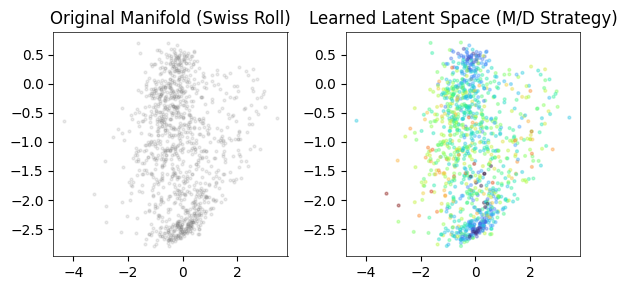

In [346]:
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.scatter(z_latents[:, 0], z_latents[:, 1], color='gray', alpha =.15, s=4)
plt.title("Original Manifold (Swiss Roll)")

plt.subplot(1, 2, 2)
plt.scatter(z_latents[:, 0], z_latents[:, 1], c=data_snr, cmap='turbo', s=4,alpha = .35)
plt.title("Learned Latent Space (M/D Strategy)")
plt.tight_layout()
plt.show()